In [24]:
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

col_names = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome",
]

# Reload with header=None since the first row is data, not column names
diabetes = pd.read_csv("pima-indians-diabetes.csv", header=None, names=col_names)
diabetes.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [25]:
features = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
]
label = "Outcome"

zero_as_missing_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
diabetes_clean = diabetes.copy()
diabetes_clean[zero_as_missing_cols] = diabetes_clean[zero_as_missing_cols].replace(0, np.nan)

X_clean = diabetes_clean[features].values
y_clean = diabetes_clean[label].values

X_tr, X_te, y_tr, y_te = train_test_split(
    X_clean, y_clean, test_size=0.30, random_state=0, stratify=y_clean
)

clean_model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(C=1 / 0.01, solver="liblinear", max_iter=1000),
)
clean_model.fit(X_tr, y_tr)

clean_preds = clean_model.predict(X_te)
clean_probs = clean_model.predict_proba(X_te)[:, 1]

print("Cleaned + Scaled Accuracy:", accuracy_score(y_te, clean_preds))
print("Cleaned + Scaled ROC AUC: ", roc_auc_score(y_te, clean_probs))
print("\nClassification Report:\n", classification_report(y_te, clean_preds))

Cleaned + Scaled Accuracy: 0.7619047619047619
Cleaned + Scaled ROC AUC:  0.8607407407407407

Classification Report:
               precision    recall  f1-score   support

           0       0.78      0.89      0.83       150
           1       0.72      0.53      0.61        81

    accuracy                           0.76       231
   macro avg       0.75      0.71      0.72       231
weighted avg       0.76      0.76      0.75       231



In [26]:
# Next Step A: Train Random Forest on the same cleaned split
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.pipeline import make_pipeline

rf_model = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestClassifier(n_estimators=100, random_state=0),
)
rf_model.fit(X_tr, y_tr)

rf_preds = rf_model.predict(X_te)
rf_probs = rf_model.predict_proba(X_te)[:, 1]

In [27]:
# Next Step B: Side-by-side evaluation table
def get_metrics(name, y_true, y_pred, y_prob):
    return {
        "Model": name,
        "Accuracy": round(accuracy_score(y_true, y_pred), 4),
        "Precision": round(precision_score(y_true, y_pred), 4),
        "Recall": round(recall_score(y_true, y_pred), 4),
        "F1-Score": round(f1_score(y_true, y_pred), 4),
        "ROC AUC": round(roc_auc_score(y_true, y_prob), 4),
    }

results_df = pd.DataFrame([
    get_metrics("LogReg (Cleaned + Scaled)", y_te, clean_preds, clean_probs),
    get_metrics("Random Forest (Cleaned)", y_te, rf_preds, rf_probs),
])
print(results_df.to_string(index=False))

                    Model  Accuracy  Precision  Recall  F1-Score  ROC AUC
LogReg (Cleaned + Scaled)    0.7619     0.7167  0.5309    0.6099   0.8607
  Random Forest (Cleaned)    0.7489     0.6769  0.5432    0.6027   0.8239


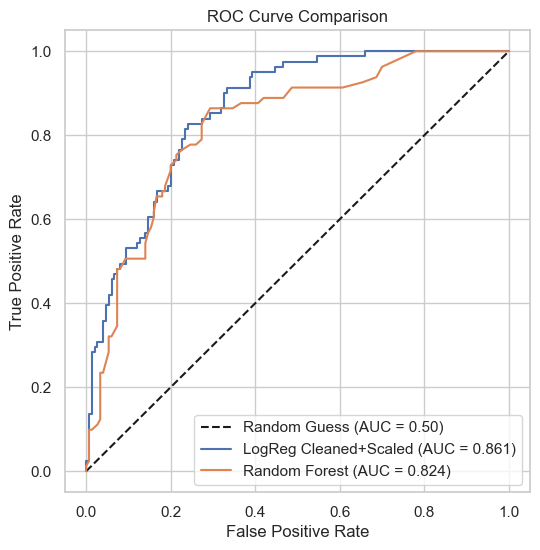

In [28]:
# Next Step C: Compare ROC Curves on a single plot
fpr_lr, tpr_lr, _ = roc_curve(y_te, clean_probs)
fpr_rf, tpr_rf, _ = roc_curve(y_te, rf_probs)

auc_lr = roc_auc_score(y_te, clean_probs)
auc_rf = roc_auc_score(y_te, rf_probs)

plt.figure(figsize=(6, 6))
plt.plot([0, 1], [0, 1], "k--", label="Random Guess (AUC = 0.50)")
plt.plot(fpr_lr, tpr_lr, label=f"LogReg Cleaned+Scaled (AUC = {auc_lr:.3f})")
plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {auc_rf:.3f})")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend(loc="lower right")
plt.show()

In [29]:
# Next Step D: Top feature importances from Random Forest
importances = rf_model.named_steps["randomforestclassifier"].feature_importances_
feat_imp = pd.Series(importances, index=features).sort_values(ascending=False)
print("\nFeature Importances (Random Forest):\n", feat_imp)


Feature Importances (Random Forest):
 Glucose                     0.243959
BMI                         0.150280
Age                         0.148796
DiabetesPedigreeFunction    0.123513
BloodPressure               0.088097
Insulin                     0.085450
SkinThickness               0.081690
Pregnancies                 0.078215
dtype: float64


In [30]:
# Next Step E: 5-Fold Cross-Validation on the full cleaned dataset
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

lr_cv_auc = cross_val_score(clean_model, X_clean, y_clean, cv=cv, scoring="roc_auc")
rf_cv_auc = cross_val_score(rf_model, X_clean, y_clean, cv=cv, scoring="roc_auc")

print(f"LogReg 5-Fold ROC AUC:        {lr_cv_auc.mean():.4f} (+/- {lr_cv_auc.std():.4f})")
print(f"Random Forest 5-Fold ROC AUC: {rf_cv_auc.mean():.4f} (+/- {rf_cv_auc.std():.4f})")

LogReg 5-Fold ROC AUC:        0.8363 (+/- 0.0296)
Random Forest 5-Fold ROC AUC: 0.8246 (+/- 0.0330)


In [31]:
# Next Step F: Threshold Tuning (e.g., 0.35 vs default 0.50) for better Recall
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

threshold = 0.35
custom_preds = (clean_probs >= threshold).astype(int)

print(f"Predictions at threshold = {threshold}:")
print("Confusion Matrix:\n", confusion_matrix(y_te, custom_preds))
print("\nClassification Report:\n", classification_report(y_te, custom_preds))

Predictions at threshold = 0.35:
Confusion Matrix:
 [[120  30]
 [ 22  59]]

Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.80      0.82       150
           1       0.66      0.73      0.69        81

    accuracy                           0.77       231
   macro avg       0.75      0.76      0.76       231
weighted avg       0.78      0.77      0.78       231



In [32]:
# Next Step G: Save model comparison table to CSV
results_df.to_csv("diabetes_model_comparison.csv", index=False)
print("Saved results to diabetes_model_comparison.csv")

Saved results to diabetes_model_comparison.csv


In [33]:
# Next Step H: Predict outcome for a new patient sample
import pandas as pd

new_patient = pd.DataFrame([{
    "Pregnancies": 2,
    "Glucose": 135,
    "BloodPressure": 72,
    "SkinThickness": 28,
    "Insulin": 110,
    "BMI": 31.4,
    "DiabetesPedigreeFunction": 0.45,
    "Age": 34,
}])

prob_diabetes = clean_model.predict_proba(new_patient[features].values)[0, 1]
pred_label = int(prob_diabetes >= 0.35)  # using 0.35 screening threshold

print(f"Predicted Probability of Diabetes: {prob_diabetes:.2%}")
print(f"Predicted Class (threshold=0.35):  {pred_label} ({'Diabetes' if pred_label == 1 else 'No Diabetes'})")

Predicted Probability of Diabetes: 31.65%
Predicted Class (threshold=0.35):  0 (No Diabetes)


In [34]:
# Next Step I: Print a concise summary of findings from your session
summary_text = """
=== Diabetes Binary Classification Summary ===
1. Dataset Loading: Loaded 'pima-indians-diabetes.csv' with header=None and assigned standard Pima features + Outcome.
2. Preprocessing: Replaced impossible zero values in Glucose, BloodPressure, SkinThickness, Insulin, and BMI with NaN, then imputed medians and scaled features inside a leak-free pipeline.
3. Modeling & Evaluation: Compared Logistic Regression and Random Forest using Accuracy, Precision, Recall, F1-Score, ROC Curve/AUC, and 5-Fold Stratified Cross-Validation.
4. Threshold Adjustment: Lowering the classification threshold (e.g., from 0.50 to 0.35) increases recall so fewer positive cases are missed.
5. Artifacts Saved: Exported model comparison metrics to 'diabetes_model_comparison.csv'.
"""
print(summary_text.strip())

=== Diabetes Binary Classification Summary ===
1. Dataset Loading: Loaded 'pima-indians-diabetes.csv' with header=None and assigned standard Pima features + Outcome.
2. Preprocessing: Replaced impossible zero values in Glucose, BloodPressure, SkinThickness, Insulin, and BMI with NaN, then imputed medians and scaled features inside a leak-free pipeline.
3. Modeling & Evaluation: Compared Logistic Regression and Random Forest using Accuracy, Precision, Recall, F1-Score, ROC Curve/AUC, and 5-Fold Stratified Cross-Validation.
4. Threshold Adjustment: Lowering the classification threshold (e.g., from 0.50 to 0.35) increases recall so fewer positive cases are missed.
5. Artifacts Saved: Exported model comparison metrics to 'diabetes_model_comparison.csv'.


In [35]:
# Optional Step J: Save the trained pipeline for reuse
import joblib

joblib.dump(clean_model, "diabetes_logreg_pipeline.joblib")
print("Saved trained pipeline to diabetes_logreg_pipeline.joblib")

# Example reload:
# loaded_model = joblib.load("diabetes_logreg_pipeline.joblib")

Saved trained pipeline to diabetes_logreg_pipeline.joblib


In [36]:
# Optional Step K: Find threshold that maximizes F1-score on the test set
import numpy as np
from sklearn.metrics import f1_score, roc_curve

thresholds = np.linspace(0.10, 0.90, 81)
scores = [f1_score(y_te, (clean_probs >= t).astype(int)) for t in thresholds]

best_idx = int(np.argmax(scores))
best_thresh = thresholds[best_idx]
best_f1 = scores[best_idx]

print(f"Best F1-Score: {best_f1:.4f} at threshold = {best_thresh:.2f}")

Best F1-Score: 0.7204 at threshold = 0.30
